In [1]:
%pip install numpy pandas matplotlib seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Идеи
- Простые категории: hotel_type, взрослые, дети, еда, market_segment, distr_chanl, повторный гость, тип комнаты, deposit_type, customer_type, 
- Численные: кол-во дней, цена, предыдущие отмены, дни ожидания, цена дня, 
- lead_time посмотреть на зависимость от времени
- Сезонность: график по одним неделям или месяцам за разные года
- 

In [3]:
df = pd.read_csv("../data/hotel_bookings.csv")

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


In [6]:
df.isna().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [7]:
df.nunique()

hotel                                2
is_canceled                          2
lead_time                          479
arrival_date_year                    3
arrival_date_month                  12
arrival_date_week_number            53
arrival_date_day_of_month           31
stays_in_weekend_nights             17
stays_in_week_nights                35
adults                              14
children                             5
babies                               5
meal                                 5
country                            177
market_segment                       8
distribution_channel                 5
is_repeated_guest                    2
previous_cancellations              15
previous_bookings_not_canceled      73
reserved_room_type                  10
assigned_room_type                  12
booking_changes                     21
deposit_type                         3
agent                              333
company                            352
days_in_waiting_list     

### Категории

Простые категории: hotel_type, взрослые, дети, еда, market_segment, distr_chanl, повторный гость, тип комнаты, deposit_type, customer_type, 

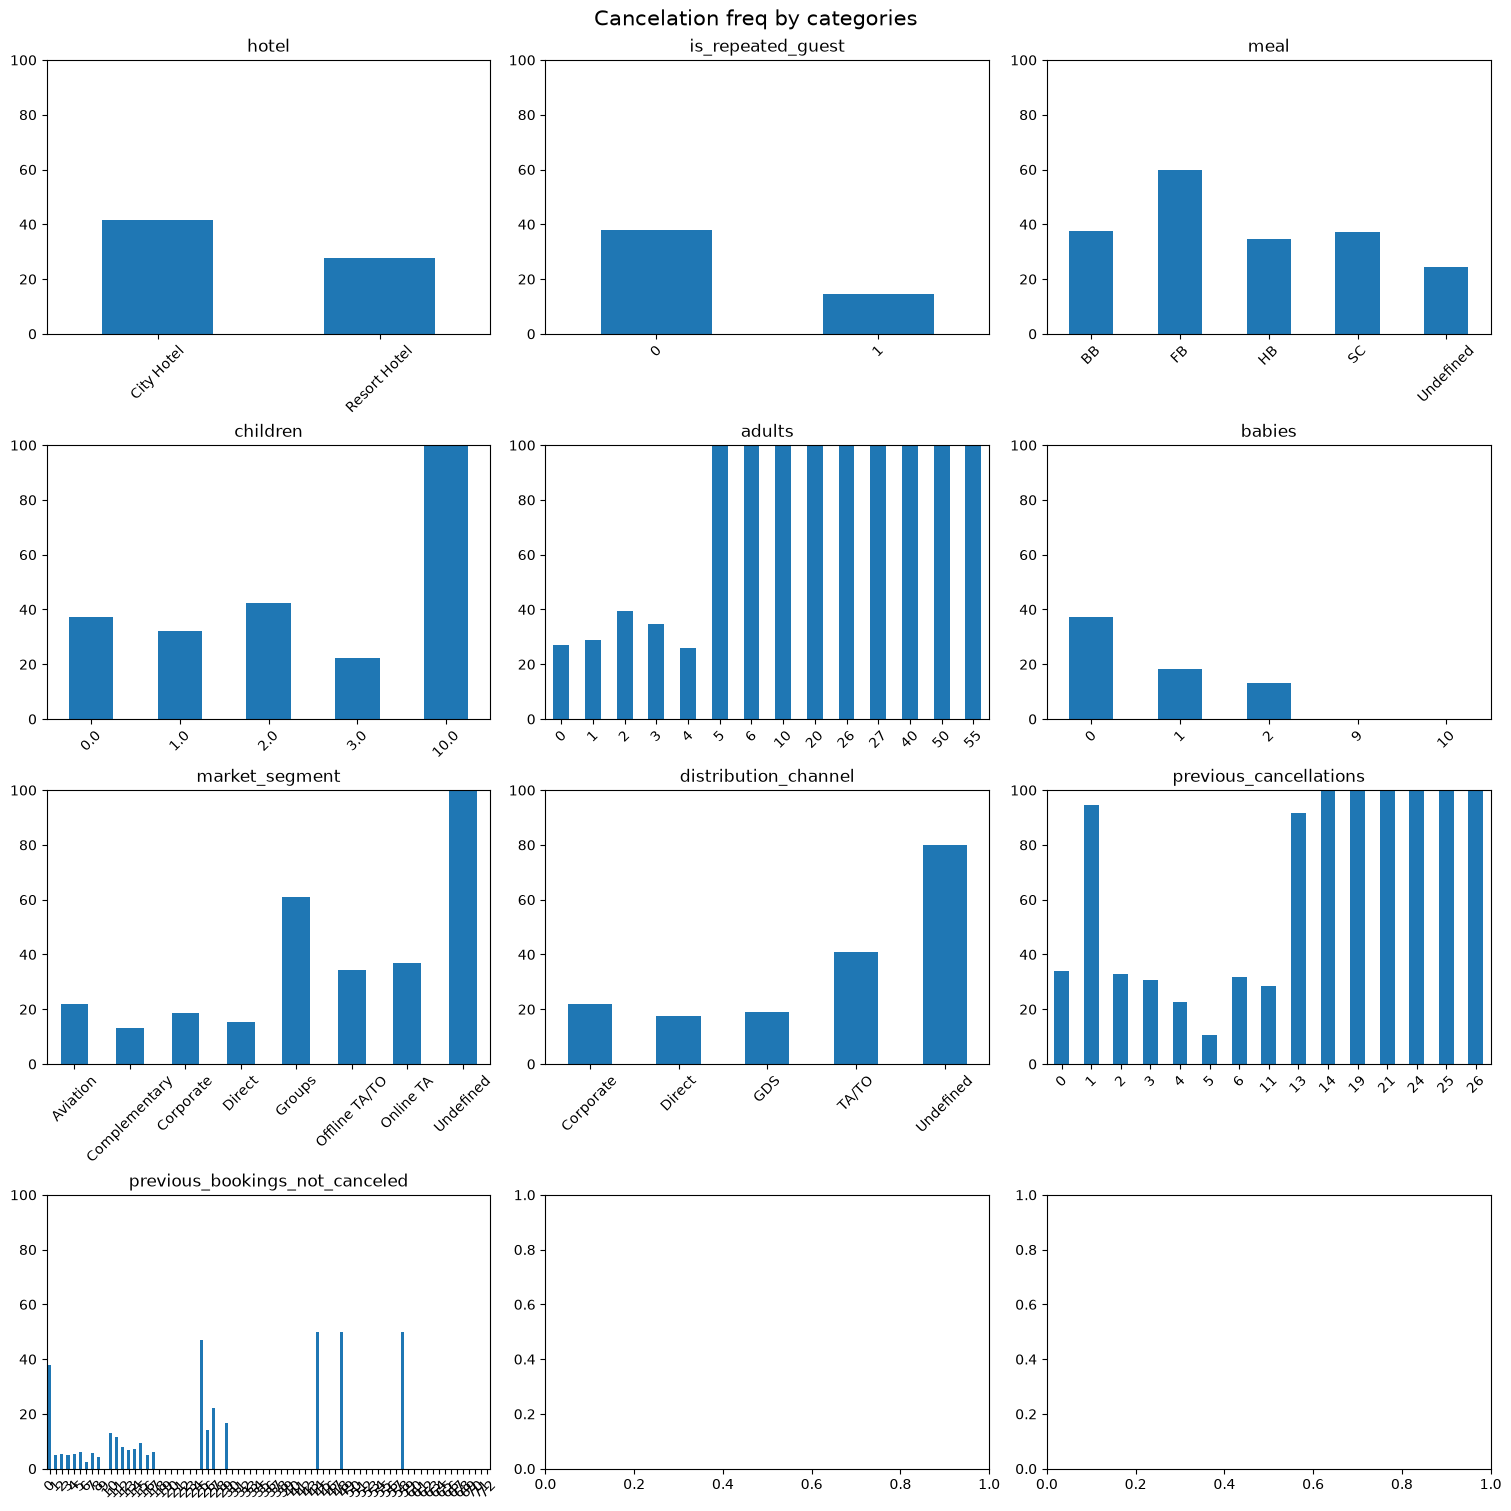

In [8]:
# fig, axes = plt.subplots(2, 3, figsize=(15, 15))
# df.groupby("hotel")["is_canceled"].mean().mul(100).plot(ax=axes[0][0], kind="bar")
# df.groupby("is_repeated_guest")["is_canceled"].mean().mul(100).plot(ax=axes[0][1], kind="bar")
# df.groupby("children")["is_canceled"].mean().mul(100).plot(ax=axes[0][2], kind="bar")

cat_stats = []

for category in ("hotel", "is_repeated_guest", "meal", "children", "adults", "babies", "market_segment", "distribution_channel", "previous_cancellations", "previous_bookings_not_canceled"):
    cat_stats.append(
        (category, 
            df.groupby(category)["is_canceled"]
            .mean()
            .mul(100)
        )
    )

fig, axes = plt.subplots(4, 3, figsize=(15, 15), layout="constrained")
fig.suptitle("Cancelation freq by categories", fontsize=15)

for (category, stats), ax in zip(cat_stats, axes.flat):
    stats.plot(ax=ax, kind="bar", ylim=(0, 100))
    ax.tick_params(axis="x", labelrotation=0)
    ax.set_title(category)
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelrotation=45)

### Отмена по численным параметрам

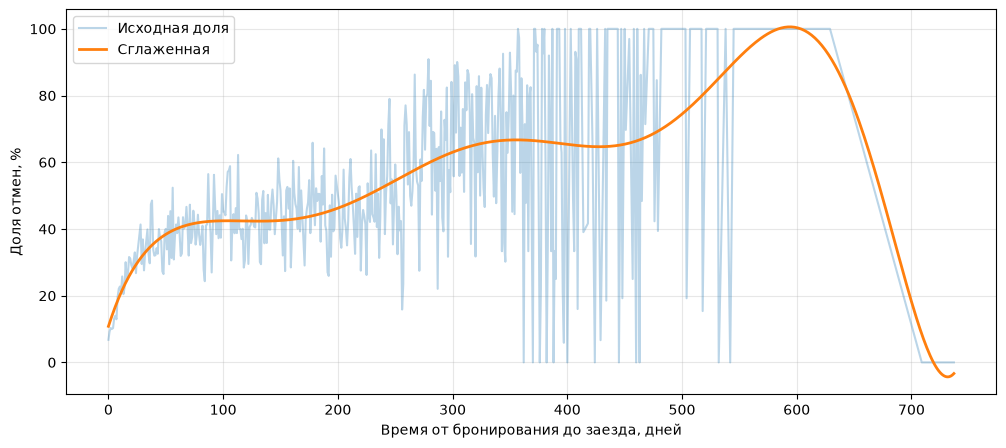

In [9]:
cancel_rate = df.groupby("lead_time")["is_canceled"].mean().mul(100)
x = cancel_rate.index.to_numpy()
y = cancel_rate.to_numpy()

degree = 10  # степень полинома
coefficients = np.polyfit(x, y, deg=degree)

x_smooth = np.linspace(x.min(), x.max(), 500)
y_smooth = np.polyval(coefficients, x_smooth)

plt.figure(figsize=(12, 5))
plt.plot(x, y, alpha=0.3, label="Исходная доля")
plt.plot(x_smooth, y_smooth, linewidth=2, label="Сглаженная")

# plt.xscale("symlog", linthresh=10)
# plt.yscale("symlog", linthresh=0.01)
plt.xlabel("Время от бронирования до заезда, дней")
plt.ylabel("Доля отмен, %")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

<Axes: ylabel='Frequency'>

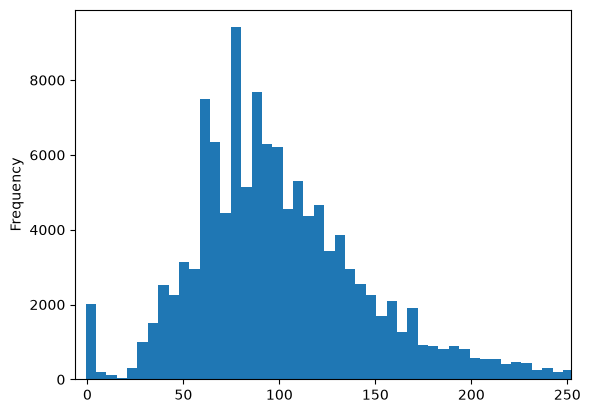

In [61]:
df["adr"].plot(kind="hist", bins=1000, xlim=(df["adr"].min(), np.percentile(df["adr"], 99)))
# df["adr"].unique()
# np.round(101.002222, decimals=-2)

                доля_отмен  бронирований
adr_bin                                 
(-inf, 0.0]       0.108673          1960
(0.0, 20.0]       0.447619           420
(20.0, 40.0]      0.212578          4516
(40.0, 60.0]      0.269810         11093
(60.0, 80.0]      0.428600         25399
(80.0, 100.0]     0.370021         24250
(100.0, 120.0]    0.393398         18541
(120.0, 140.0]    0.398916         12920
(140.0, 160.0]    0.362478          7457
(160.0, 180.0]    0.378941          4948
(180.0, 200.0]    0.369631          2957
(200.0, 220.0]    0.378115          1846
(220.0, 240.0]    0.398986          1381
(240.0, 260.0]    0.400000           780


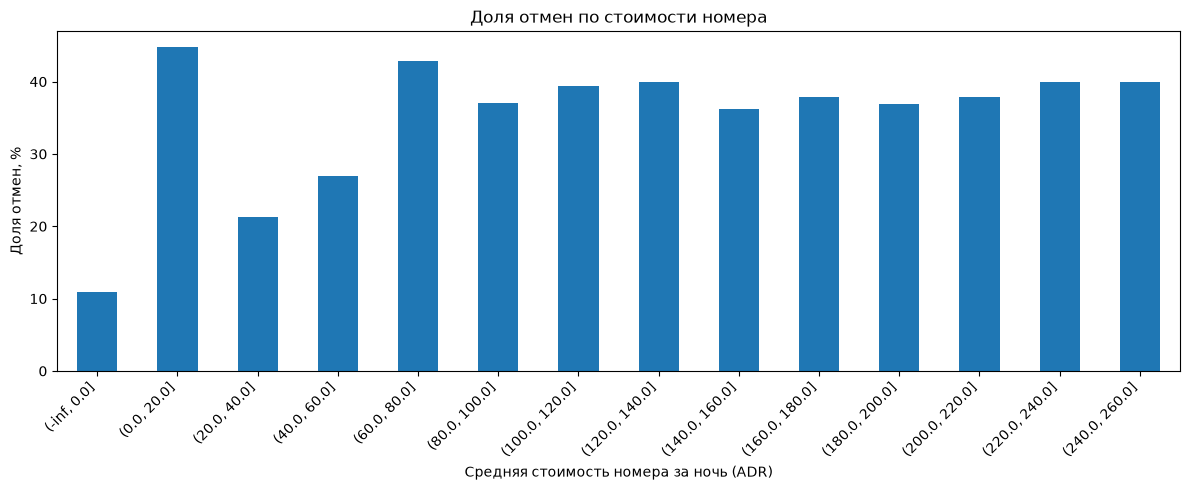

In [82]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Верхняя граница графика — 99-й перцентиль
upper = df["adr"].quantile(0.99)
upper = np.ceil(upper / 20) * 20

# Отдельная корзина для нуля, затем интервалы по 20
bins = [-np.inf, 0] + list(np.arange(20, upper + 1, 20))

data = df.copy()
data["adr_bin"] = pd.cut(data["adr"], bins=bins)

stats = data.groupby("adr_bin", observed=True)["is_canceled"].agg(
    доля_отмен="mean",
    бронирований="count"
)

print(stats)

ax = (stats["доля_отмен"] * 100).plot(
    kind="bar", figsize=(12, 5)
)
ax.set_xlabel("Средняя стоимость номера за ночь (ADR)")
ax.set_ylabel("Доля отмен, %")
ax.set_title("Доля отмен по стоимости номера")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()